<a href="https://colab.research.google.com/github/TWAPZCODE/Quant-Research/blob/main/asymptotic_behaviour_of_asset_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Asymptotic Behaviour of Asset Prices in options trading: continuous-Time Hedging.

In theoretical models, perfect Delta hedging requires continuous adjustment of the underlying asset position.

This can be viewed as the limit of discrete hedging (e.g., adjusting once a day) as the time interval Δt→0.

firstly a brief walkthrough of limits.

For a function f(x), we say the limit of f(x) as x approaches c equals L (written as lim_{x→c} f(x) = L) if and only if:

For every ε > 0, there exists a δ > 0 such that if 0 < |x - c| < δ, then |f(x) - L| < ε.

In formal logical notation: ∀ε > 0, ∃δ > 0 such that ∀x ∈ dom(f), (0 < |x - c| < δ ⟹ |f(x) - L| < ε)

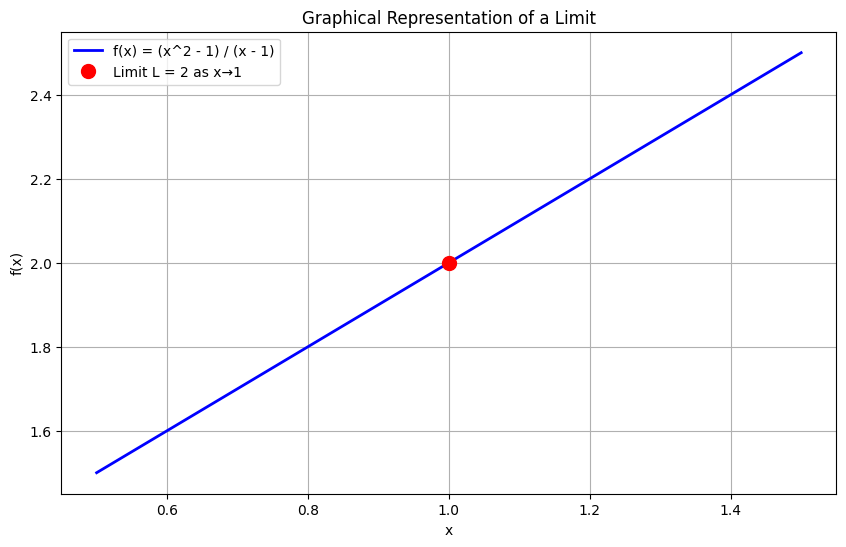

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Basic Limit Visualization
def f(X):
      return (x**2 - 1) / (x - 1)  # returns nan at x=1

x = np.linspace(0.5, 1.5, 1000)
y = f(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, 'b-', linewidth=2, label='f(x) = (x^2 - 1) / (x - 1)')

# Mark the hole at (1, 2)
plt.plot(1, 2, 'ro', markersize=10, label='Limit L = 2 as x→1')

plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Graphical Representation of a Limit')
plt.legend()
plt.grid(True)
plt.show()


Adding Epsilon-Delta Visual:

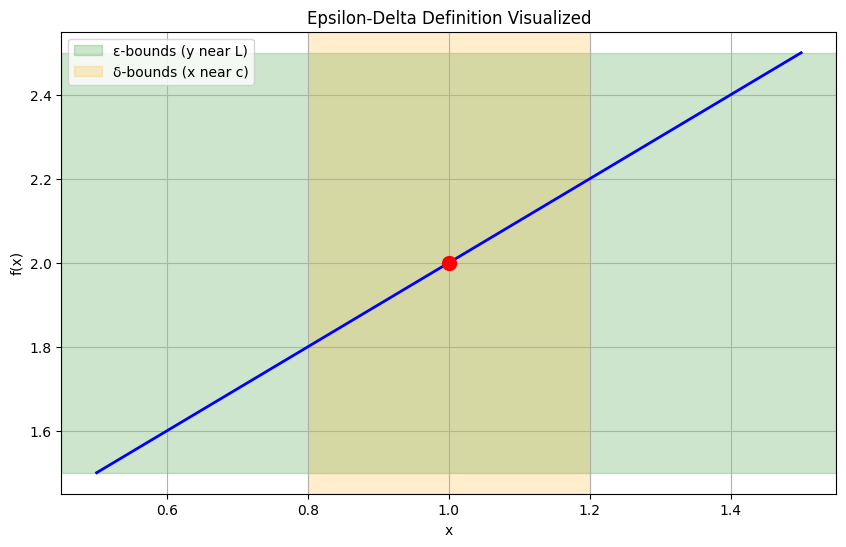

In [ ]:
# 2. Epsilon-Delta Visualization
eps = 0.5
delta = 0.2
L = 2
c = 1

plt.figure(figsize=(10, 6))
plt.plot(x, y, 'b-', linewidth=2)
plt.axhspan(L - eps, L + eps, alpha=0.2, color='green', label='ε-bounds (y near L)')
plt.axvspan(c - delta, c + delta, alpha=0.2, color='orange', label='δ-bounds (x near c)')
plt.plot(1, 2, 'ro', markersize=10)
plt.xlabel('x'); plt.ylabel('f(x)')
plt.title('Epsilon-Delta Definition Visualized')
plt.legend()
plt.grid(True)
plt.show()

Visualizing Convergence to a Horizontal Asymptote, with another function that accomodates this demonstaration

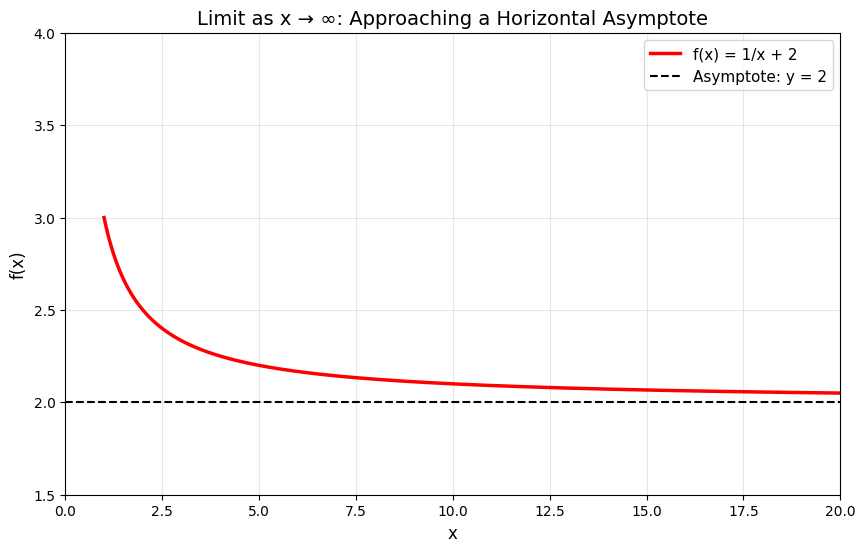

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(1, 20, 1000)
y = 1/x + 2  # Asymptote at y = 2

plt.figure(figsize=(10, 6))
plt.plot(x, y, 'r-', linewidth=2.5, label='f(x) = 1/x + 2')

# Draw the horizontal asymptote
plt.axhline(y=2, color='black', linestyle='--', linewidth=1.5, label='Asymptote: y = 2')

plt.xlabel('x', fontsize=12)
plt.ylabel('f(x)', fontsize=12)
plt.title('Limit as x → ∞: Approaching a Horizontal Asymptote', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0, 20)
plt.ylim(1.5, 4)
plt.show()

Epsilon-delta at a finite point: showing how δ shrinks as ε shrinks for f(x) = 1/x + 2 at x₀ = 1

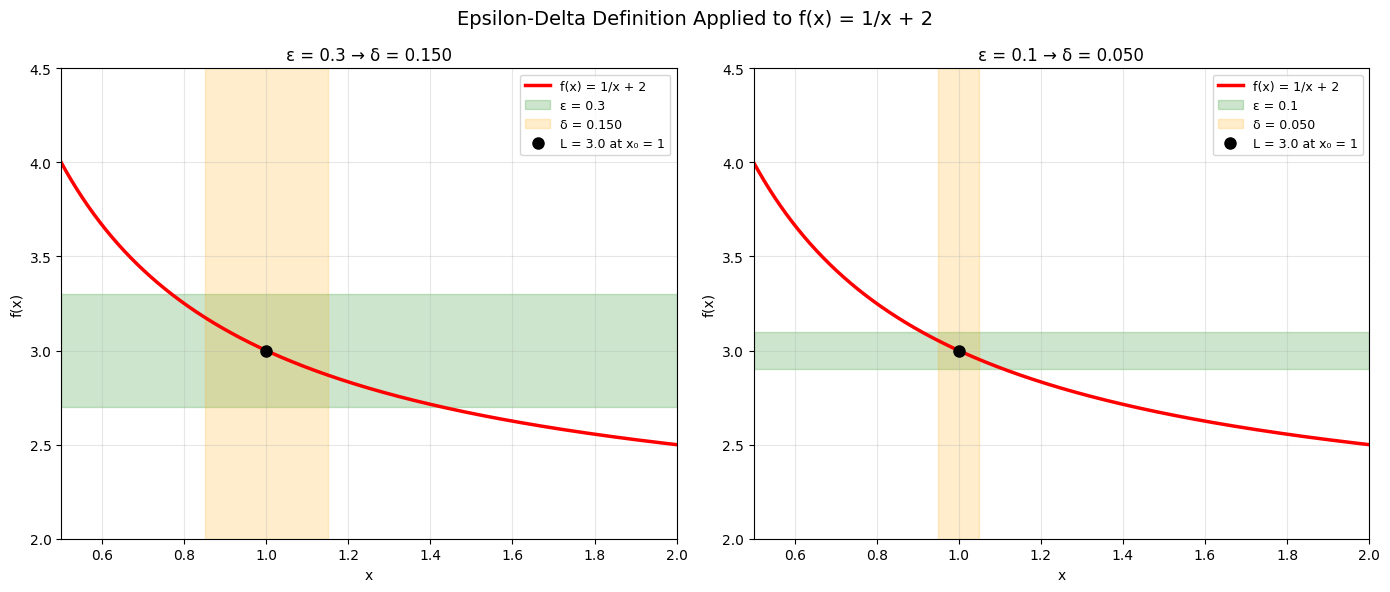

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 1/x + 2

x0 = 1
L = f(x0)

x = np.linspace(0.5, 2, 1000)
y = f(x)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, eps in zip(axes, [0.3, 0.1]):
    delta = min(x0/2, eps * x0**2 / 2)  # derived so |f(x)-L| < eps whenever |x-x0| < delta

    ax.plot(x, y, 'r-', linewidth=2.5, label='f(x) = 1/x + 2')
    ax.axhspan(L - eps, L + eps, alpha=0.2, color='green', label=f'ε = {eps}')
    ax.axvspan(x0 - delta, x0 + delta, alpha=0.2, color='orange', label=f'δ = {delta:.3f}')
    ax.plot(x0, L, 'ko', markersize=8, label=f'L = {L} at x₀ = {x0}')

    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.set_title(f'ε = {eps} → δ = {delta:.3f}')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.5, 2)
    ax.set_ylim(2, 4.5)

fig.suptitle('Epsilon-Delta Definition Applied to f(x) = 1/x + 2', fontsize=14)
plt.tight_layout()
plt.show()

## Delta Hedging

Now to set my variables foroptions trading, The goal of Delta Hedging is to make a portfolio completely risk-neutral.

### Notation: Delta Hedging

Let $V(S,t)$ denote the value of an option written on an underlying asset with price $S$ at time $t$. A hedged portfolio holding one option and short $\Delta$ units of the underlying is

$$\Pi = V(S,t) - \Delta S$$

where the hedge ratio (delta) is

$$\Delta = \frac{\partial V}{\partial S}$$

Choosing $\Delta$ this way makes the portfolio instantaneously insensitive to small moves in $S$, i.e. $\partial \Pi / \partial S = 0$ — this is the risk-neutral (delta-neutral) condition. In practice $\Delta$ changes as $S$ and $t$ change, so the hedge must be rebalanced; continuous-time hedging is the idealised limit of doing this rebalancing infinitely often, as introduced above.

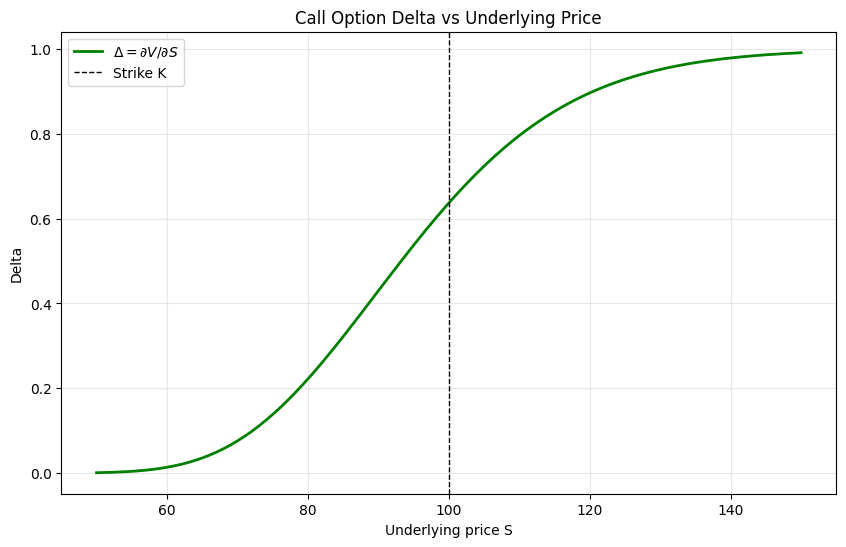

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

def bs_call_delta(S, K, T, r, sigma):
      d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
      return norm.cdf(d1)

K, T, r, sigma = 100, 1.0, 0.05, 0.2
S_range = np.linspace(50, 150, 200)
deltas = bs_call_delta(S_range, K, T, r, sigma)

plt.figure(figsize=(10, 6))
plt.plot(S_range, deltas, 'g-', linewidth=2, label=r'$\Delta = \partial V/\partial S$')
plt.axvline(K, color='black', linestyle='--', linewidth=1, label='Strike K')
plt.xlabel('Underlying price S')
plt.ylabel('Delta')
plt.title('Call Option Delta vs Underlying Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Delta rises from near 0 (deep out-of-the-money, the option is worthless so hedging it needs almost no stock) to near 1 (deep in-the-money, the option moves nearly one-for-one with the stock, so it behaves like holding the stock outright). Near the strike, delta is most sensitive to $S$ — this is exactly where rebalancing needs to happen most frequently, which is why continuous hedging matters most around at-the-money options.

## From a Discrete Limit to the Continuous Black–Scholes Model

The Black–Scholes model can itself be seen as a limit. Take the binomial option pricing model: over each small step $\Delta t$, the stock either moves up by factor $u$ or down by factor $d$, and a replicating (delta-hedged) portfolio is formed at each step. As the number of steps $n \to \infty$ (equivalently $\Delta t \to 0$) over a fixed horizon $T$, with $u,d$ calibrated to the volatility $\sigma$, the discrete binomial price converges to the continuous Black–Scholes price — the same $\varepsilon$–$\delta$ style limiting argument from the opening section, now applied to a pricing model instead of a single function.

In the continuous limit the option value $V(S,t)$ satisfies the Black–Scholes PDE:

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS\frac{\partial V}{\partial S} - rV = 0$$

This PDE is derived by delta-hedging continuously (holding $\Delta = \partial V/\partial S$ units of stock at every instant) and letting the hedging interval shrink to zero, which eliminates the portfolio's exposure to the random term and leaves only the deterministic PDE above.

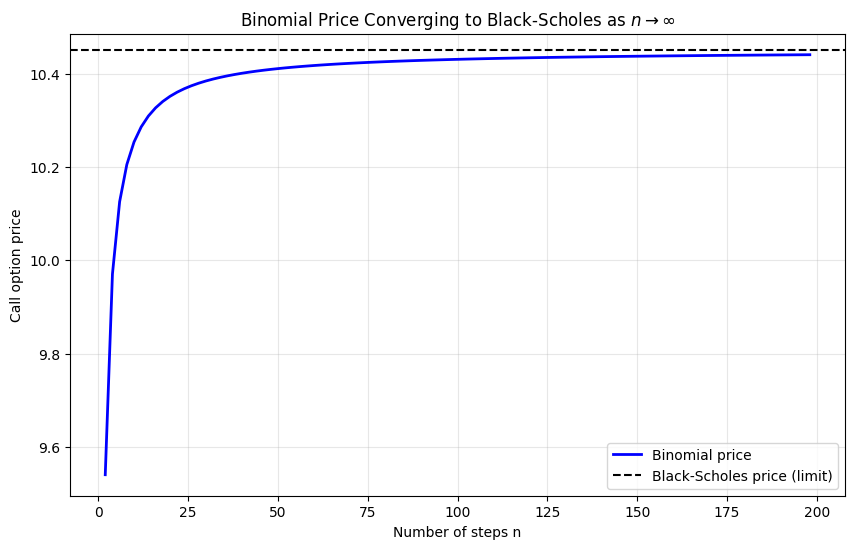

In [ ]:
def binomial_call_price(S0, K, T, r, sigma, n):
    dt = T / n
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)
    disc = np.exp(-r * dt)

    # terminal stock prices
    j = np.arange(n + 1)
    ST = S0 * u**(n - j) * d**j
    payoff = np.maximum(ST - K, 0)

    # backward induction
    for _ in range(n):
        payoff = disc * (p * payoff[:-1] + (1 - p) * payoff[1:])
    return payoff[0]

def bs_call_price(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

S0 = 100
steps = np.arange(2, 200, 2)
binom_prices = [binomial_call_price(S0, K, T, r, sigma, n) for n in steps]
bs_price = bs_call_price(S0, K, T, r, sigma)

plt.figure(figsize=(10, 6))
plt.plot(steps, binom_prices, 'b-', linewidth=2, label='Binomial price')
plt.axhline(bs_price, color='black', linestyle='--', linewidth=1.5, label='Black-Scholes price (limit)')
plt.xlabel('Number of steps n')
plt.ylabel('Call option price')
plt.title(r'Binomial Price Converging to Black-Scholes as $n \to \infty$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

As $n$ grows, the discrete rebalancing dates get closer together — $\Delta t \to 0$ — and the binomial price settles onto the flat Black–Scholes line. This is a direct, numerical instance of the limit definition from the start of the notebook: for any tolerance $\varepsilon > 0$ there is a step count $n$ large enough that the binomial price stays within $\varepsilon$ of the Black–Scholes price for all larger $n$. It's the same convergence argument, just applied to a hedging and pricing scheme rather than a single function $f(x)$.

# Assumptions and Limitations of the Black–Scholes Model

Everything above was priced and hedged for a **single European option** on a single underlying — that scope matters, because Black–Scholes is only exact under a fairly restrictive set of assumptions:

**Assumptions**
- The underlying follows geometric Brownian motion: log-returns are normally distributed with constant drift and constant volatility $\sigma$.
- The risk-free rate $r$ is constant and known over the option's life.
- No dividends are paid on the underlying during the option's life.
- Markets are frictionless: no transaction costs or taxes, unlimited short selling, and the underlying is infinitely divisible.
- Trading is continuous, so the delta hedge can be rebalanced at every instant (this is exactly the $\Delta t \to 0$ limit built up earlier in the notebook).
- No arbitrage opportunities exist.
- The option is European — exercisable only at maturity.

**Limitations**
- **Constant volatility is unrealistic.** Real implied volatility varies by strike and maturity (the volatility smile/skew), which Black–Scholes cannot produce internally.
- **Returns aren't lognormal in practice** — real return distributions have fatter tails and can jump discontinuously (e.g. overnight gaps), which the diffusion assumption misses entirely.
- **Continuous hedging is an idealisation.** Real hedging happens at discrete intervals with transaction costs, so the perfect replication argument only holds approximately — this is the practical gap between the discrete binomial model and the continuous limit shown earlier.
- **Constant rates and no dividends** rarely hold exactly over an option's life, especially for longer-dated contracts.
- **Liquidity and market microstructure effects** (bid-ask spreads, slippage, margin constraints) are ignored, but matter a lot for actual futures/options hedging.
- More fundamentally, the model assumes efficient, memoryless price dynamics. Markets that exhibit persistent trending behaviour (e.g. Hurst exponent significantly away from 0.5) violate the random-walk premise the model is built on.

## Extending to a Portfolio: Hedging NQ Futures Drawdowns with Multiple Options

The single-option case above hedges one instrument against one source of risk (delta). A real hedging problem — like protecting an NQ futures position against a drawdown — usually involves **multiple** options (different strikes and/or maturities) hedging **multiple** risk exposures (delta *and* gamma) simultaneously.

This generalises naturally into a linear algebra problem. If a portfolio holds a futures position plus $n$ options, its aggregate delta and gamma are just the position-weighted sums of the individual Greeks. Requiring the portfolio to be simultaneously delta-neutral and gamma-neutral gives a small system of linear equations:

$$A\mathbf{x} = \mathbf{b}, \qquad A = \begin{pmatrix} \Delta_1 & \Delta_2 \\ \Gamma_1 & \Gamma_2 \end{pmatrix}, \quad \mathbf{b} = \begin{pmatrix} -\Delta_{futures} \\ -\Gamma_{futures} \end{pmatrix}$$

**A naive `numpy.linalg.solve` on this system is unsafe.** Solving it exactly for two puts unconstrained can hand back a *ratio* spread — long one strike, **short** more contracts of the other — which is a naked short position in the tail. That structure matches the local Greeks perfectly at $S_0$ but actively *amplifies* losses in a severe drawdown, which defeats the entire purpose of hedging. The fix is to add a **long-only constraint** ($\mathbf{x} \geq 0$, no naked short options) and solve the constrained problem instead, via non-negative least squares (`scipy.optimize.nnls`) rather than a plain square solve. We also apply NQ's real futures/options multiplier of \$20 per index point, and round to whole contracts, since fractional contracts aren't tradeable.

Long-only hedge -> put@19500: 2.99 -> 3 contracts, put@19000: 0.00 -> 0 contracts (NNLS residual: 0.00054)
Achieved delta: -1.0000 (target -1.0)
Achieved gamma: 0.000544 (target -0.0)


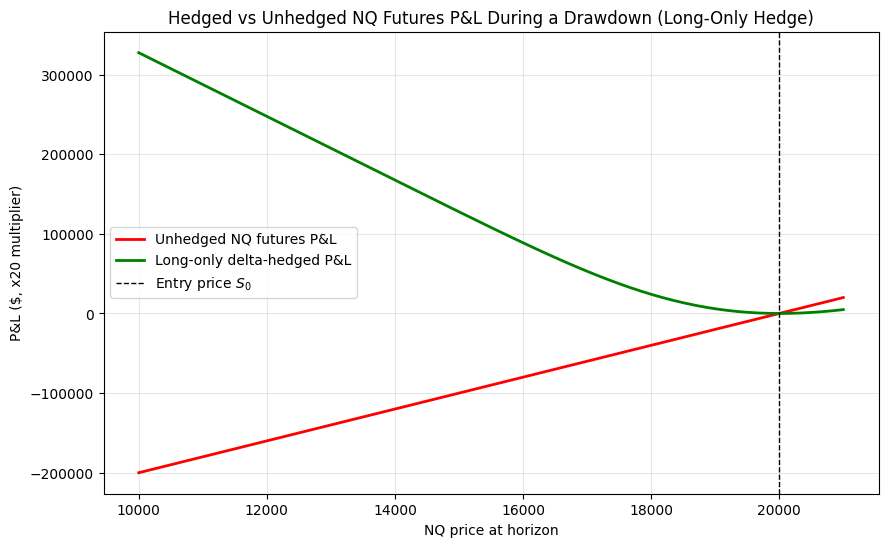

In [ ]:
from scipy.optimize import nnls

def bs_put_delta(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return norm.cdf(d1) - 1

def bs_gamma(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return norm.pdf(d1) / (S * sigma * np.sqrt(T))

def bs_put_price(S, K, T, r, sigma):
    S = np.asarray(S, dtype=float)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

MULTIPLIER = 20  # NQ futures/options: $20 per index point

# NQ futures position: long 1 contract, delta = 1, gamma = 0
S0, r, sigma, T = 20000, 0.05, 0.20, 0.25
futures_delta, futures_gamma = 1.0, 0.0

# Two OTM puts as candidate hedge instruments
K1, K2 = 19500, 19000
d1_ = bs_put_delta(S0, K1, T, r, sigma)
d2_ = bs_put_delta(S0, K2, T, r, sigma)
g1 = bs_gamma(S0, K1, T, r, sigma)
g2 = bs_gamma(S0, K2, T, r, sigma)

A = np.array([[d1_, d2_],
              [g1,  g2]])
b = np.array([-futures_delta, -futures_gamma])

# Long-only solve: no naked short legs allowed
x_raw, residual = nnls(A, b)
x = np.round(x_raw)  # whole contracts only
print(f"Long-only hedge -> put@{K1}: {x_raw[0]:.2f} -> {int(x[0])} contracts, "
      f"put@{K2}: {x_raw[1]:.2f} -> {int(x[1])} contracts (NNLS residual: {residual:.5f})")
print(f"Achieved delta: {d1_*x_raw[0] + d2_*x_raw[1]:.4f} (target {-futures_delta})")
print(f"Achieved gamma: {g1*x_raw[0] + g2*x_raw[1]:.6f} (target {-futures_gamma})")

# Simulate portfolio P&L across a drawdown in the underlying, in real dollar terms
S_range = np.linspace(10000, 21000, 200)
futures_pnl = MULTIPLIER * (S_range - S0)
put1_pnl = MULTIPLIER * x[0] * (bs_put_price(S_range, K1, T, r, sigma) - bs_put_price(S0, K1, T, r, sigma))
put2_pnl = MULTIPLIER * x[1] * (bs_put_price(S_range, K2, T, r, sigma) - bs_put_price(S0, K2, T, r, sigma))
hedged_pnl = futures_pnl + put1_pnl + put2_pnl

plt.figure(figsize=(10, 6))
plt.plot(S_range, futures_pnl, 'r-', linewidth=2, label='Unhedged NQ futures P&L')
plt.plot(S_range, hedged_pnl, 'g-', linewidth=2, label='Long-only delta-hedged P&L')
plt.axvline(S0, color='black', linestyle='--', linewidth=1, label='Entry price $S_0$')
plt.xlabel('NQ price at horizon')
plt.ylabel('P&L ($, x20 multiplier)')
plt.title('Hedged vs Unhedged NQ Futures P&L During a Drawdown (Long-Only Hedge)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()